# Multivariate uncertainty

**Every series in a forecast can look right on its own while the forecast as a whole is wrong.** Suppose you forecast temperature and electricity demand together, and each forecast's spread is spot on. If your sample paths pair hot days with low demand, any decision that uses both at once, such as how much capacity to keep for a hot, busy afternoon, is planned around futures that won't happen.

Sample paths exist to carry that pairing: each sample is one possible future for every series and every step together. Scores that look at one series and one step at a time can't tell whether the pairing is right.

In this notebook we take a correct forecast of two linked series, scramble which values go together while leaving each series' distribution untouched, and see which scores notice. Then we ask TimeGym's covariance check, and repeat everything on 32 new cases.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import Scenario
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast
from timegym.statistics import paired_t_interval, wilson_interval

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"Answer key": "#009E73", "Scrambled": "#D55E00"}

## Two series that move together

Both series revert to their means (`ar1`), like the series in the previous notebook, and their shocks are linked: the surprises that hit `y0` and `y1` at the same step have a correlation of 0.85. When `y0` jumps up, `y1` usually jumps up too. Think of `y0` as temperature and `y1` as demand.

Because we generated the data, we hold the **answer key**: the true joint distribution of the next 6 steps of both series. We draw 128 sample paths from it, so we start from a forecast that is right by construction. Each sample is one possible future for both series over all 6 steps; the whole array is 128 × 6 × 2 (samples, steps, series).

In [2]:
HORIZON, N_SAMPLES = 6, 128
scenario = Scenario("ar1", context_length=160, horizon=HORIZON, n_targets=2,
                    parameters={"mean": [0.0, 1.0], "phi": 0.8,
                                "sigma": [1.0, 0.7], "correlation": 0.85}, seed=29)
case = scenario.generate()
good = case.reference.forecast(n_samples=N_SAMPLES, seed=1029)

Here are both series, with the same five sample paths drawn in both panels: a path's color on the left matches its color on the right.

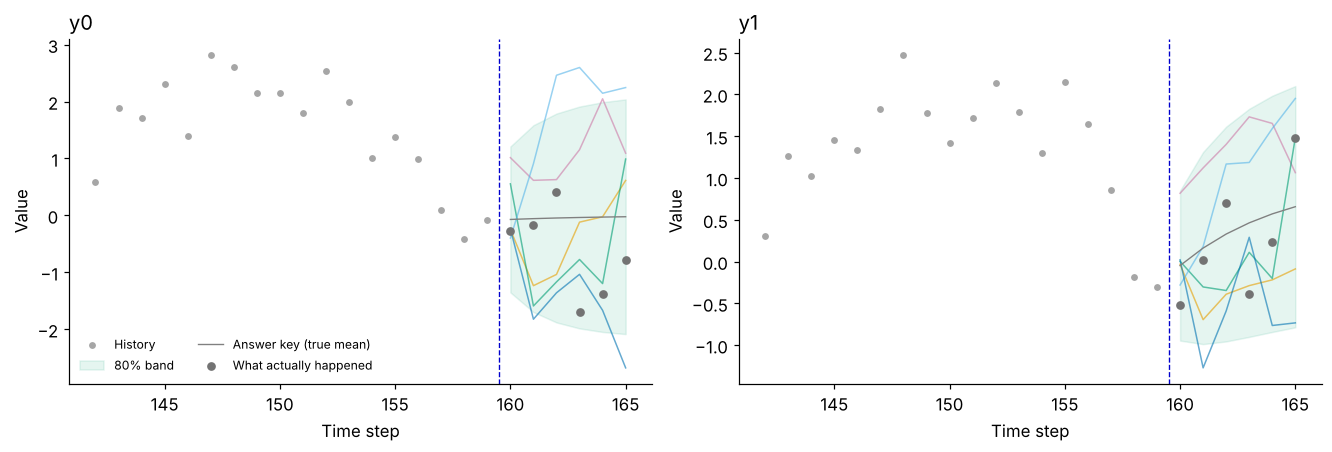

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
future = case.task.future_index.to_numpy()
path_colors = ["#CC79A7", "#E69F00", "#009E73", "#56B4E9", "#0072B2"]
for target, ax in enumerate(axes):
    history = case.task.context.iloc[-18:, target]
    ax.scatter(history.index, history, color="0.65", s=12, label="History")
    ax.fill_between(future, good.quantiles[:, target, 0], good.quantiles[:, target, -1],
                    color=COLORS["Answer key"], alpha=0.10, label="80% band")
    for sample, color in enumerate(path_colors):
        ax.plot(future, good.samples[sample, :, target], color=color, alpha=0.6, linewidth=1.0)
    ax.plot(future, case.reference.mean[:, target], color="0.5", linewidth=0.9, label="Answer key (true mean)")
    ax.scatter(future, case.observed.iloc[:, target], color="0.45", s=22,
               label="What actually happened", zorder=3)
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
    ax.set(title=case.task.target_names[target], xlabel="Time step", ylabel="Value")
axes[0].legend(fontsize=8, ncol=2, loc="lower left")
plt.show()

Each color is one sample: a single possible future for both series at once. Because the shocks are linked, a path that runs high in `y0` tends to run high in `y1` as well.

## Scramble the pairing

Now the bug. TimeGym's `dependence_shuffle` fault takes one series at one step and shuffles its 128 values among the samples, then does the same, independently, for every other series and step. Each series at each step keeps exactly the same 128 values, so its histogram, its quantiles and its best guess don't change. What changes is which values travel together. Real pipelines break the pairing in similar ways by accident: drawing each series separately, sorting each series' samples on its own, or resampling one series without the other.

In [4]:
scrambled = mutate_forecast(good, "dependence_shuffle", seed=2029)
forecasts = {"Answer key": good, "Scrambled": scrambled}

np.testing.assert_array_equal(np.sort(scrambled.samples, axis=0), np.sort(good.samples, axis=0))  # same values
np.testing.assert_array_equal(scrambled.point, good.point)          # same best guesses
np.testing.assert_array_equal(scrambled.quantiles, good.quantiles)  # same quantiles
print("Each series at each step keeps the same 128 values.")
print(f"Yet single sample values moved by up to {np.max(np.abs(scrambled.samples - good.samples)):.2f}.")

Each series at each step keeps the same 128 values.
Yet single sample values moved by up to 6.36.


## What the scramble did

To see the damage, plot the two series' values at step 3 against each other. Each dot is one sample.

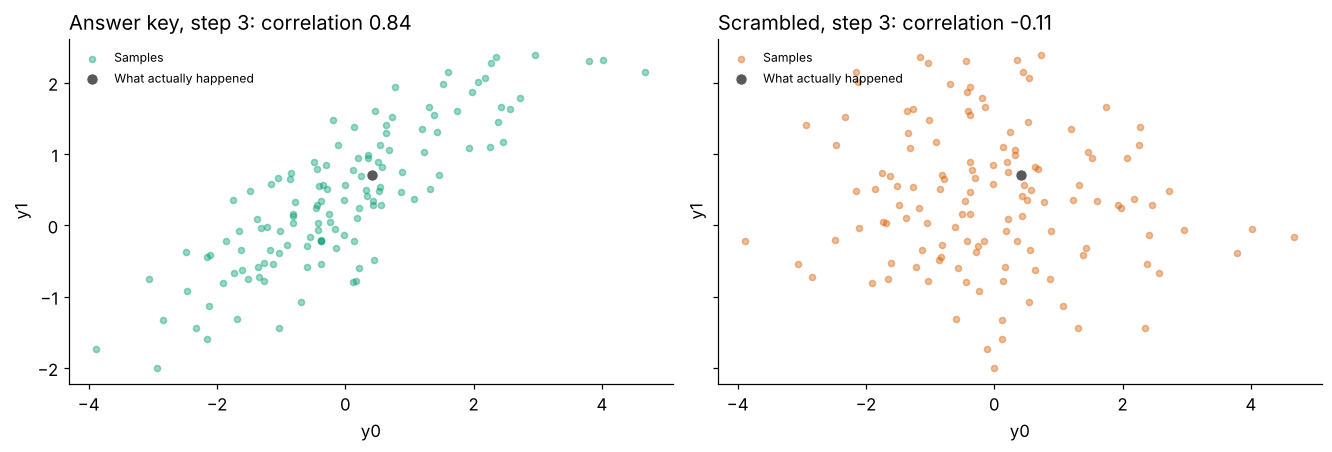

Answer key: 12 of 128 samples have both series above their 90% quantile.
Scrambled: 0 of 128 samples have both series above their 90% quantile.


In [5]:
step = 2  # the third step ahead
observed = case.observed.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True, layout="constrained")
for ax, (name, forecast) in zip(axes, forecasts.items()):
    values = forecast.samples[:, step, :]
    correlation = np.corrcoef(values.T)[0, 1]
    ax.scatter(values[:, 0], values[:, 1], s=16, alpha=0.4, color=COLORS[name], label="Samples")
    ax.scatter(*observed[step], s=55, color="0.35", edgecolors="white",
               linewidths=0.6, label="What actually happened", zorder=4)
    ax.set(title=f"{name}, step {step + 1}: correlation {correlation:.2f}",
           xlabel=case.task.target_names[0], ylabel=case.task.target_names[1])
    ax.legend(fontsize=8, loc="upper left")
plt.show()

for name, forecast in forecasts.items():
    high = forecast.samples[:, step, :] > forecast.quantiles[step, :, -1]  # above each series' 90% quantile
    print(f"{name}: {high.all(axis=1).sum()} of {N_SAMPLES} samples have both series above their 90% quantile.")

In the answer key the cloud tilts: a high `y0` comes with a high `y1`. After the scramble the same values form a round blob with no tilt. Now ask each forecast how likely it is that both series are high at once, the hot and busy afternoon. In the answer key, 12 of the 128 samples have both series above their 90% quantile; in the scrambled forecast, built from exactly the same values, none do.

The scatter shows one step. The full picture is a table of correlations between all 12 numbers in a sample (6 steps × 2 series). On the left are the true correlations; in the middle, those measured from the answer key's 128 samples; on the right, from the scrambled samples.

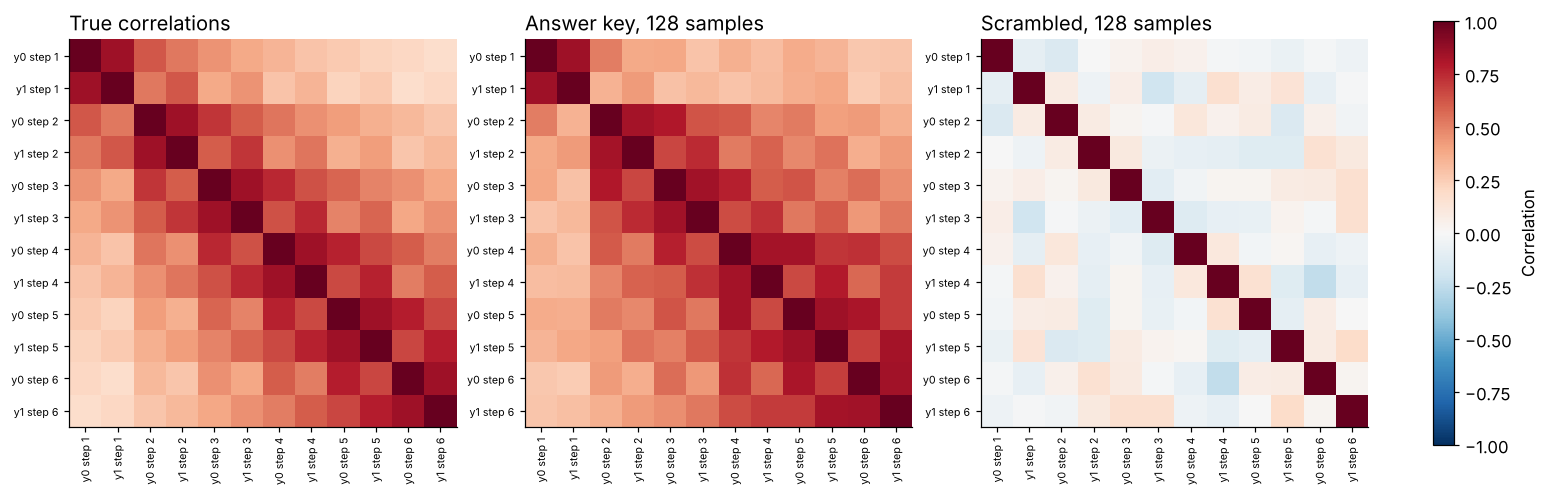

In [6]:
labels = [f"{name} step {h + 1}" for h in range(HORIZON) for name in case.task.target_names]


def correlation_table(covariance):
    sd = np.sqrt(np.diag(covariance))
    return covariance / np.outer(sd, sd)


def sample_covariance(samples):
    return np.cov(samples.reshape(len(samples), -1), rowvar=False)


tables = {"True correlations": correlation_table(case.reference.covariance),
          "Answer key, 128 samples": correlation_table(sample_covariance(good.samples)),
          "Scrambled, 128 samples": correlation_table(sample_covariance(scrambled.samples))}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9), layout="constrained")
for ax, (title, table) in zip(axes, tables.items()):
    image = ax.imshow(table, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=title, xticks=np.arange(len(labels)), yticks=np.arange(len(labels)),
           xticklabels=labels, yticklabels=labels)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
fig.colorbar(image, ax=axes, shrink=0.8, label="Correlation")
plt.show()

The answer key's samples reproduce the true pattern, up to sampling noise: strong links between the two series at the same step, and links between nearby steps that fade with distance, because shocks fade. The scrambled samples keep only the diagonal, each number with itself. Every other link is gone: between the series, and between steps of the same series.

## Which scores notice?

Now score both forecasts against what actually happened with TimeGym's `evaluate_forecast`. MAE, MSE and CRPS score each series at each step on its own. Two scores look at whole samples instead:

- The **energy score** (`energy_score`) treats each sample as one point in 12 dimensions and asks how close the cloud of samples sits to what actually happened. It is CRPS for whole paths.
- The **variogram score** (`variogram_score`) looks at pairs of numbers within a sample, such as `y0` and `y1` at step 3, or `y0` at steps 2 and 3, and checks whether the typical gap between them matches the gap that actually happened.

All five are losses: lower is better.

In [7]:
SCORES = {"mae": "MAE", "mse": "MSE", "crps": "CRPS",
          "energy_score": "Energy score", "variogram_score": "Variogram score"}
results = {name: evaluate_forecast(case, forecast) for name, forecast in forecasts.items()}
one_case = pd.DataFrame({name: {label: result.metrics[key] for key, label in SCORES.items()}
                         for name, result in results.items()}).T
np.testing.assert_allclose(one_case.loc["Scrambled", ["MAE", "MSE", "CRPS"]],
                           one_case.loc["Answer key", ["MAE", "MSE", "CRPS"]], rtol=1e-12)  # blind to pairing
display(one_case.round(4))

,MAE,MSE,CRPS,Energy score,Variogram score
Answer key,0.6283,0.6105,0.4452,1.9335,0.1183
Scrambled,0.6283,0.6105,0.4452,1.9099,0.1324


MAE, MSE and CRPS are identical, as they must be. The variogram score is worse for the scrambled forecast (0.132 against 0.118). The energy score, though, prefers the scrambled one on this case (1.910 against 1.934). Whole-path scores respond to the pairing, but weakly, and on one case luck can outweigh it.

## Ask TimeGym

TimeGym has a check aimed at exactly this bug: `reference_covariance`. It compares the samples with the answer key directly, so it only works when you have one, as here. Turn it on with `check_dependence=True`. In plain words:

1. From the samples, estimate the covariance: the 12 × 12 table of how every number in a sample moves with every other.
2. Measure how far it is from the answer key's true table, as a fraction of the true table's size (a normalized Frobenius distance). Zero means identical.
3. Find out how far a correct forecast lands by chance: draw 99 fresh sets of 128 samples from the answer key itself (`n_calibration=99`) and measure each one the same way.
4. The p-value is the share of all 100 distances, the 99 correct ones plus the forecast's own, that are at least as large as the forecast's. With 99 sets the smallest possible p-value is 0.01. At or below 0.05 (`alpha`), the check FAILs.

In [8]:
CHECK = dict(check_dependence=True, n_calibration=99, alpha=0.05)
checked = {name: evaluate_forecast(case, forecast, dependence_seed=4029, **CHECK)
           for name, forecast in forecasts.items()}
display(pd.DataFrame({name: {d.name: d.status for d in result.diagnostics}
                      for name, result in checked.items()}))

covariance = {name: next(d for d in result.diagnostics if d.name == "reference_covariance")
              for name, result in checked.items()}
assert covariance["Scrambled"].status == "FAIL"  # TimeGym catches the scramble
# No assert that the answer key passes: a correct forecast fails 5% of the time by chance.
display(pd.DataFrame({name: {"distance from the true covariance": d.evidence["statistic"],
                             "critical value (95th of 99 correct distances)": d.evidence["critical_value"],
                             "p-value": d.evidence["p_value"]}
                      for name, d in covariance.items()}).round(3))

,Answer key,Scrambled
forecast_contract,PASS,PASS
point_accuracy,INCONCLUSIVE,INCONCLUSIVE
quantile_accuracy,INCONCLUSIVE,INCONCLUSIVE
interval_coverage,INCONCLUSIVE,INCONCLUSIVE
sample_scores,INCONCLUSIVE,INCONCLUSIVE
reference_covariance,PASS,FAIL


,Answer key,Scrambled
distance from the true covariance,0.132,0.870
critical value (95th of 99 correct distances),0.262,0.262
p-value,0.640,0.010


Both forecasts pass the output checks (`forecast_contract`), and their scores are INCONCLUSIVE as in the previous notebook: scored, but no pass mark was set. The covariance check splits them. The answer key's samples are 0.13 from the true covariance, well short of the critical value of 0.26 that only the farthest few of the 99 correct sets reach, so they PASS (p-value 0.64). The scrambled samples are 0.87 away, beyond all 99 correct sets, so they get the smallest possible p-value, 0.01, and FAIL.

## Thirty-two new cases

One case can be lucky either way. We repeat the experiment on 32 new cases: new history, a new answer-key forecast, a new scramble, and both forecasts scored and checked.

In [9]:
N_CASES = 32
rows = []
for seed in range(500, 500 + N_CASES):
    run = scenario.generate(seed=seed)
    good_run = run.reference.forecast(n_samples=N_SAMPLES, seed=10_000 + seed)
    for name, prediction in [("Answer key", good_run),
                             ("Scrambled", mutate_forecast(good_run, "dependence_shuffle", seed=20_000 + seed))]:
        result = evaluate_forecast(run, prediction, dependence_seed=30_000 + seed, **CHECK)
        check = next(d for d in result.diagnostics if d.name == "reference_covariance")
        rows.append({"case": seed, "forecast": name, "covariance check failed": check.status == "FAIL",
                     **{label: result.metrics[key] for key, label in SCORES.items()}})
per_case = pd.DataFrame(rows)

First, how often did the covariance check fail each forecast? For the answer key every failure is a false alarm. The 95% intervals (Wilson intervals) show how far each rate could move by chance with 32 cases.

In [10]:
rates = []
for name, group in per_case.groupby("forecast", sort=False):
    share = wilson_interval(group["covariance check failed"].to_numpy())
    rates.append({"forecast": name, "failed": f"{share['count']} of {share['n']}",
                  "rate": share["rate"], "95% interval": f"{share['ci95'][0]:.2f} to {share['ci95'][1]:.2f}"})
display(pd.DataFrame(rates).set_index("forecast").round(3))
assert per_case.loc[per_case["forecast"] == "Scrambled", "covariance check failed"].all()  # never missed

,failed,rate,95% interval
forecast,,,
Answer key,1 of 32,0.031,0.01 to 0.16
Scrambled,32 of 32,1.000,0.89 to 1.00


The check failed the scrambled forecast in all 32 cases, and the answer key in 1, in line with the 5% false-alarm rate it allows (1.6 of 32 on average).

Next, the scores. As in the previous notebook, we subtract within each case, so each case's luck cancels; a positive difference means the scrambled forecast did worse.

In [11]:
rows, differences = [], {}
for score in SCORES.values():
    table = per_case.pivot(index="case", columns="forecast", values=score)
    differences[score] = np.round(table["Scrambled"] - table["Answer key"], 10).to_numpy() + 0.0  # drop float noise
    interval = paired_t_interval(differences[score])
    rows.append({"score": score, **table[list(forecasts)].mean().round(4),
                 "scrambled minus answer key": round(interval["mean"], 4),
                 "95% interval": f"{interval['ci95'][0]:.3f} to {interval['ci95'][1]:.3f}",
                 "cases where scrambled scored better": int((differences[score] < 0).sum())})
display(pd.DataFrame(rows).set_index("score"))
assert all((differences[score] == 0).all() for score in ["MAE", "MSE", "CRPS"])  # blind in every case

,Answer key,Scrambled,scrambled minus answer key,95% interval,cases where scrambled scored better
score,,,,,
MAE,0.9237,0.9237,0.0000,0.000 to 0.000,0
MSE,1.3587,1.3587,0.0000,0.000 to 0.000,0
CRPS,0.6634,0.6634,0.0000,0.000 to 0.000,0
Energy score,2.7175,2.7932,0.0757,0.047 to 0.105,4
Variogram score,0.1628,0.1941,0.0313,0.016 to 0.046,9


Each dot below is one case's difference; the cross is the average with its 95% interval.

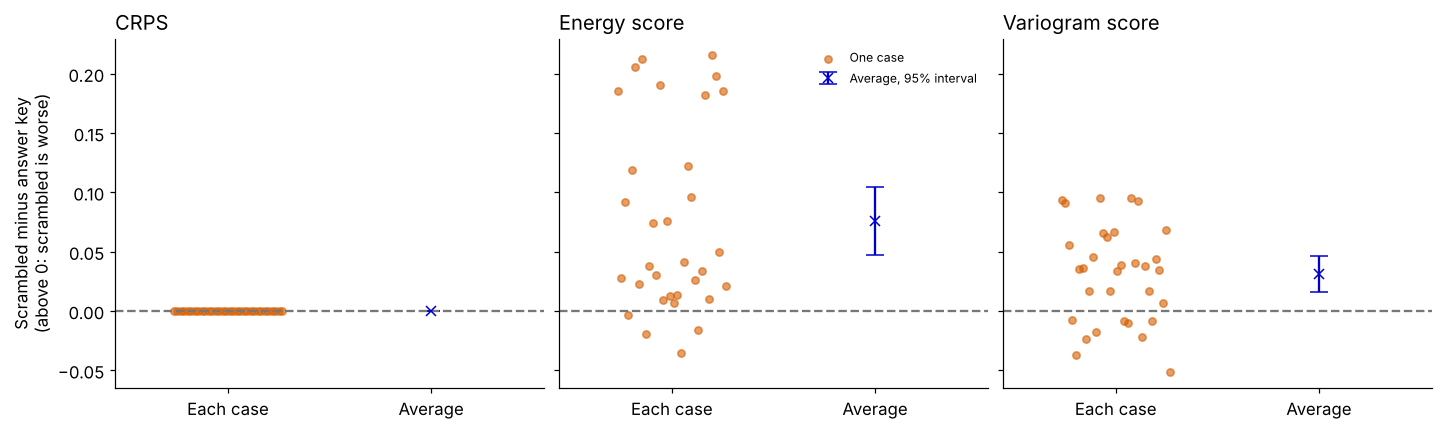

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, score in zip(axes, ["CRPS", "Energy score", "Variogram score"]):
    interval = paired_t_interval(differences[score])
    x = np.linspace(-0.12, 0.12, N_CASES)  # fixed spread so the dots don't overlap
    ax.scatter(x, differences[score], s=23, alpha=0.6, color=COLORS["Scrambled"], label="One case")
    ax.errorbar(0.45, interval["mean"], yerr=[[interval["mean"] - interval["ci95"][0]],
                                              [interval["ci95"][1] - interval["mean"]]],
                fmt="x", capsize=6, color="#0000CC", markersize=6, label="Average, 95% interval")
    ax.axhline(0, color="#777777", linestyle="--")
    ax.set(title=score, xticks=[0, 0.45], xticklabels=["Each case", "Average"], xlim=(-0.25, 0.7))
axes[0].set_ylabel("Scrambled minus answer key\n(above 0: scrambled is worse)")
axes[1].legend(fontsize=8)
plt.show()

CRPS is blind in every single case. Both whole-path scores are worse for the scrambled forecast on average, with intervals clearly above zero: the energy score by 0.076 (0.047 to 0.105) and the variogram score by 0.031 (0.016 to 0.046). Case by case, though, they are noisy: the energy score preferred the scrambled forecast in 4 of the 32 cases, and the variogram score in 9. The covariance check, which compares against the answer key, never missed.

## What you learned

- A forecast can get every series at every step right and still get the joint future wrong. MAE, MSE, CRPS and quantiles can't see it.
- Whole-path scores (energy and variogram) notice on average, but weakly; a single case can point the wrong way.
- With an answer key, TimeGym's covariance check catches a scrambled pairing reliably.
- Once samples are scrambled, nothing downstream can unscramble them: the pairing isn't in the per-series distributions. Keep each sample whole through every transform, sort, resample and save.

## Change one thing

- Set `correlation` to 0. The series are no longer linked, but each still remembers its own past, so the scramble still breaks the links between steps. Then also set `phi` to 0: is the scramble still detectable?
- Scramble only some of the samples by passing `strength=0.5` to both `mutate_forecast` calls.
- Add a third series (`n_targets=3`, with a third entry in `mean` and `sigma`). Series on very different scales dominate the energy score, so put them on comparable scales first.
- Score a fitted model such as `GaussianAR1Forecaster`, which draws both series' shocks together. The covariance check compares it with the true process, so its estimation errors count against it too.

**What this doesn't show.** The covariance check needs an answer key, so it works on simulated data; on real data you still have the energy and variogram scores. It looks only at covariances: a FAIL says the spread or the links are off, not which (a forecast that is simply too narrow fails too), and a PASS doesn't prove the whole joint distribution is right. Each check allows a 5% false-alarm rate on its own, so across many checks some correct forecasts will fail. The intervals assume independent cases, which rolling windows over one real series are not.

Reading: [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437) · [Scheuerer and Hamill (2015)](https://doi.org/10.1175/MWR-D-14-00269.1).

**Next:** [Capability sweeps](25_capability_sweeps.ipynb).